# Valid layouts, valid grids, and exact task success

A layout proves where a proposed transform reads and writes. It does not prove
that the transform is the rule hidden in a puzzle. For transpose:

$$R(r,c)=rW+c,\qquad D(r,c)=cH+r.$$

**Evidence:** a synthetic transpose illustration, then 15 recorded conditions on
the same four public puzzles. [Study and contract](../docs/studies.md#arc).

Transpose coverage passes; this does not select transpose over reflection.


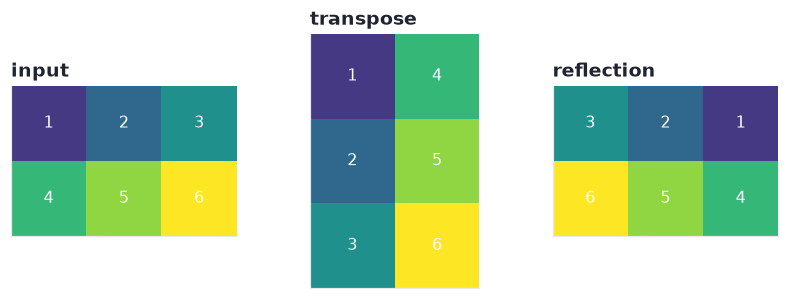

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "xcalibur").is_dir():
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT), str(ROOT / "notebooks")]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import xcalibur as xc
from style import C, SEQ, MUTED, INK, DATA, save, note
x = np.array([[1, 2, 3], [4, 5, 6]])
height, width = x.shape
out = np.empty((width, height), dtype=int)
written = []
for row in range(height):
    for col in range(width):
        read_address, write_address = row * width + col, col * height + row
        out.flat[write_address] = x.flat[read_address]
        written.append(write_address)
assert sorted(written) == list(range(x.size)) and np.array_equal(out, x.T)
reflection = x[:, ::-1]
assert out.shape != reflection.shape
print("Transpose coverage passes; this does not select transpose over reflection.")
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, grid, title in zip(axes, [x, out, reflection], ["input", "transpose", "reflection"]):
    ax.imshow(grid, vmin=0, vmax=6, cmap="viridis")
    for (r,c), value in np.ndenumerate(grid): ax.text(c, r, str(value), ha="center", va="center", color="white")
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
save(fig, "arc_layout_example"); plt.show()


## Keep the denominator visible

Count exact tasks separately from rows tagged `valid_grid_predictions`. Other
conditions return programs or post-hoc replays, so this validity count is not a
measure of all successful tool executions. Budgets differ across conditions;
the comparison is descriptive, not causal. Sixty rows are still four puzzles.

,tasks,valid_grid_rows,exact_top1,exact_top2
condition,,,,
c1_vision_t07_initial,4,4,0.0,0.0
c1_vision_t07_repair,4,4,0.0,0.0
graph_native,4,0,0.0,0.0
graph_program_replay,4,0,0.0,0.0
mined_ast_optional_16k,4,0,0.0,0.0
mined_ast_required_16k,4,0,0.0,0.0
plain_codesign_t07_initial,4,2,0.0,0.0
plain_codesign_t07_repair,4,2,0.0,0.0
plain_direct_16k,4,3,0.0,0.0


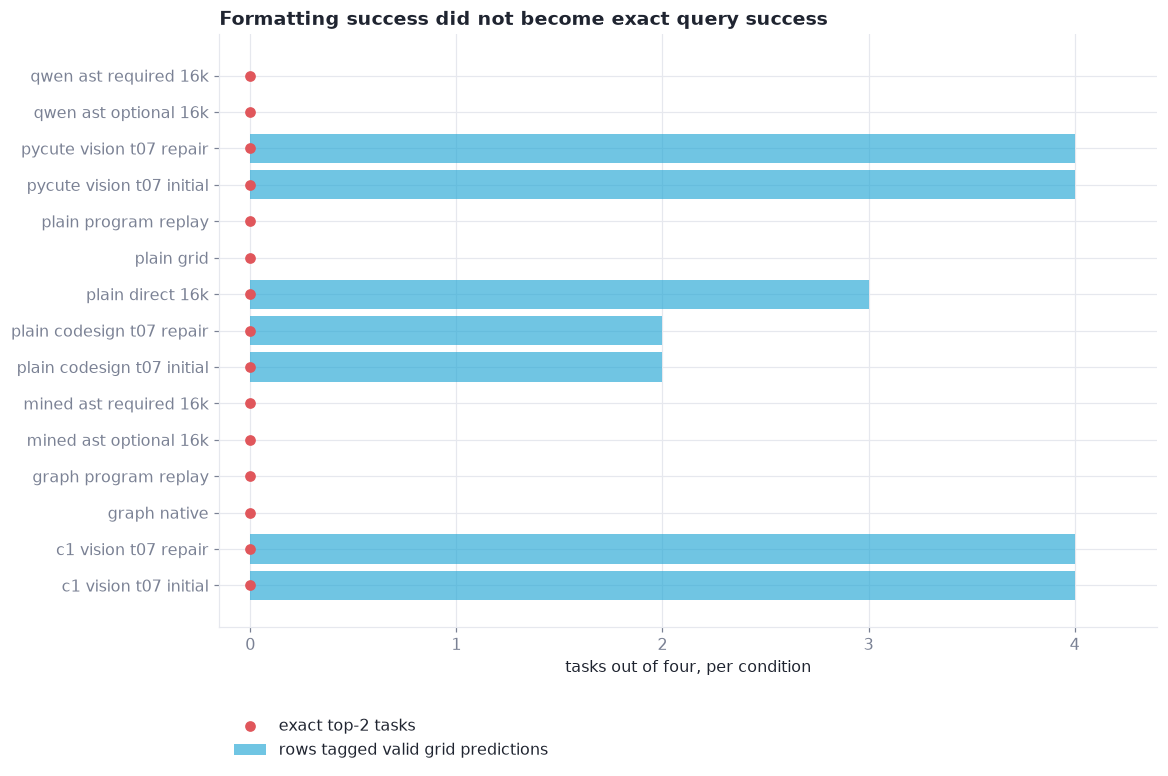

In [2]:
arc = pd.read_csv(DATA / "arc_transfer.csv")
assert arc.task.nunique() == 4 and arc.condition.nunique() == 15 and len(arc) == 60
assert not arc.duplicated(["condition", "task"]).any()
arc["valid_grid_row"] = arc.status.eq("valid_grid_predictions").astype(int)
summary = arc.groupby("condition").agg(tasks=("task", "nunique"),
    valid_grid_rows=("valid_grid_row", "sum"), exact_top1=("pass1", "sum"), exact_top2=("pass2", "sum"))
assert (summary.tasks == 4).all() and (summary.exact_top2 == 0).all()
display(summary)
fig, ax = plt.subplots(figsize=(11, 7))
y = np.arange(len(summary))
ax.barh(y, summary.valid_grid_rows, color=C["cyan"], alpha=.65, label="rows tagged valid grid predictions")
ax.scatter(summary.exact_top2, y, color=C["bad"], zorder=3, label="exact top-2 tasks")
ax.set_yticks(y, [s.replace("_", " ") for s in summary.index])
ax.set_xticks(range(5)); ax.set_xlim(-.15, 4.4)
ax.set_xlabel("tasks out of four, per condition")
ax.set_title("Formatting success did not become exact query success")
ax.legend(loc="upper left", bbox_to_anchor=(0, -.13))
save(fig, "arc_transfer_results"); plt.show()


The reusable boundary is `fit(demonstrations) -> state -> solve(state,
query_input) -> freeze -> score`. Demonstration replay is an admission check;
query labels belong to the scorer. Interrupted attempts and post-hoc replays
retain their own status. A valid map, a successful execution and useful task
performance are separate claims. [Evidence guide](../docs/studies.md#evidence).

[Notebook guide](README.md) · [Documentation](../docs/README.md#reading-order) · [Data provenance](../data/README.md)